# 06 — PCA feature reduction on the Iris dataset

This separate exercise applies **Principal Component Analysis (PCA)** to the required Iris dataset. PCA combines correlated measurements into a smaller number of new axes while preserving as much variation as possible. We standardize first because petal measurements use different scales than sepal measurements.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

iris = load_iris(as_frame=True)
X = iris.data
y = iris.target
print("Original shape:", X.shape)
display(X.head())

Original shape: (150, 4)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [2]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
print("Reduced shape:", X_2d.shape)
print("Explained variance by component:", pca.explained_variance_ratio_.round(4))
print("Total variance retained:", f"{pca.explained_variance_ratio_.sum():.1%}")

Reduced shape: (150, 2)
Explained variance by component: [0.7296 0.2285]
Total variance retained: 95.8%


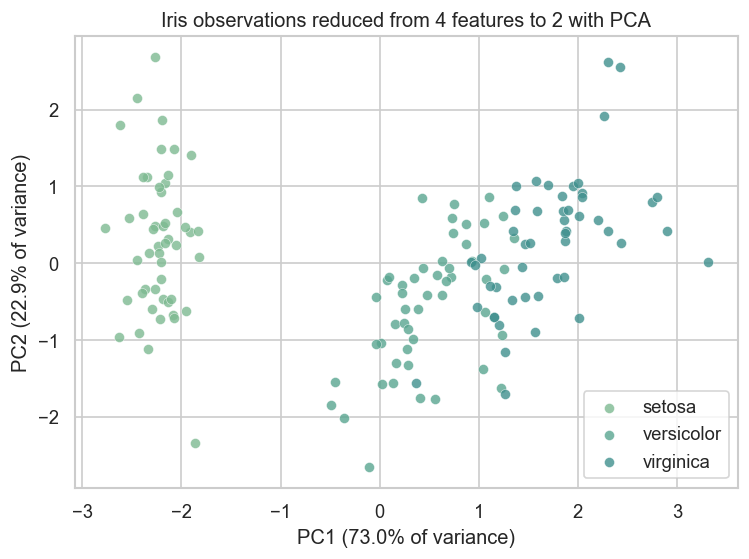

In [3]:
plot_df = pd.DataFrame(X_2d, columns=["PC1", "PC2"])
plot_df["species"] = pd.Categorical.from_codes(y, iris.target_names)
for species, part in plot_df.groupby("species"):
    plt.scatter(part.PC1, part.PC2, label=species, alpha=.8, edgecolor="white", linewidth=.3)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("Iris observations reduced from 4 features to 2 with PCA")
plt.legend()
plt.tight_layout()
plt.show()

### What the plot means
Each point is one flower; color shows its known species. The PCA axes are combinations of the four original measurements, not new physical measurements. The 2D result is easier to plot, but it discards some information. PCA is unsupervised: it does not use the species labels to choose its components.
